In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

#import numpy as np # linear algebra
#import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

#import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
#    for filename in filenames:
#        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

#import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os, json, random, hashlib, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

from sklearn.model_selection import train_test_split


from pathlib import Path
import shutil


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import losses
from tensorflow.keras import callbacks
from tensorflow.keras import layers
from tensorflow.keras import optimizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Conv2D , MaxPooling2D , Dropout , BatchNormalization , Dense , Input , Flatten
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.applications import EfficientNetB0 , ResNet50 ,  MobileNetV2 , DenseNet121


SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

In [2]:
ROOT = Path("/kaggle/input/datasets/salmansajid05/oral-diseases")

# ORIGINAL image folders only (the *_augmented_* / preview folders are offline copies).
CLASS_FOLDERS = {
    "Calculus": ROOT / "Calculus/Calculus",
    "Caries": ROOT / "Data caries/Data caries/caries orignal data set/done",
    "Gingivitis": ROOT / "Gingivitis/Gingivitis",
    "Hypodontia": ROOT / "hypodontia/hypodontia",
    "Mouth Ulcer": ROOT / "Mouth Ulcer/Mouth Ulcer/ulcer original dataset/ulcer original dataset",
    "Tooth Discoloration": ROOT / "Tooth Discoloration/Tooth Discoloration /tooth discoloration original dataset/tooth discoloration original dataset",
}
EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

IMG_SIZE = (224, 224)
BATCH = 32
NUM_CLASSES = len(CLASS_FOLDERS)

WORK = Path("/kaggle/working")
MODEL_DIR = WORK / "models"

In [3]:
def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

rows = []
for label, folder in CLASS_FOLDERS.items():
    if not Path(folder).exists():
        raise FileNotFoundError(folder)
    for p in sorted(Path(folder).rglob("*")):
        if p.is_file() and p.suffix.lower() in EXTS:
            rows.append((str(p), label))          # label comes from the class folder we chose

df = pd.DataFrame(rows, columns=["path", "label"])
print("raw images:", len(df))
print(df.label.value_counts(), "\n")

# 1) exact duplicates (same bytes)
df["md5"] = df.path.map(md5)
n_lab = df.groupby("md5").label.nunique()
conflict = n_lab[n_lab > 1].index
print("identical images that appear under more than one class:", len(conflict))
df = df[~df.md5.isin(conflict)]               # ambiguous label -> drop

before = len(df)
df = df.drop_duplicates("md5").reset_index(drop=True)
print("exact duplicates removed:", before - len(df))

raw images: 5563
label
Gingivitis             2349
Calculus               1296
Hypodontia             1251
Mouth Ulcer             265
Caries                  219
Tooth Discoloration     183
Name: count, dtype: int64 

identical images that appear under more than one class: 392
exact duplicates removed: 546


In [4]:
# 2) near-duplicates: 64-bit difference hash of each image AND of its mirror image
def dhash_bits(img, size=8):
    g = img.convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).ravel().astype(np.float32)

H, HF, keep = [], [], []
for i, p in enumerate(df.path):
    try:
        with Image.open(p) as im:
            im = im.convert("RGB")
            H.append(dhash_bits(im))
            HF.append(dhash_bits(ImageOps.mirror(im)))
        keep.append(i)
    except Exception:
        print("unreadable, dropped:", p)
df = df.iloc[keep].reset_index(drop=True)
H, HF = np.stack(H), np.stack(HF)

def hamming(A, B):                      # A:(n,64) B:(m,64) 0/1 floats -> (n,m) distances
    return A @ (1 - B).T + (1 - A) @ B.T

NEAR_DUP_THRESHOLD = 4                  # bits out of 64; raise to group more aggressively
parent = np.arange(len(df))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

for s in range(0, len(df), 512):
    e = min(s + 512, len(df))
    d = np.minimum(hamming(H[s:e], H), hamming(H[s:e], HF))
    ii, jj = np.where(d <= NEAR_DUP_THRESHOLD)
    for a, b in zip(ii + s, jj):
        if a < b:
            union(a, b)

df["group"] = [find(i) for i in range(len(df))]
print("images:", len(df), "| independent groups:", df.group.nunique())

# near-identical photos labelled as different classes = label noise -> drop them
g_lab = df.groupby("group").label.nunique()
bad = g_lab[g_lab > 1].index
print("groups spanning several classes:", len(bad), "->", int(df.group.isin(bad).sum()), "images dropped")
df = df[~df.group.isin(bad)].reset_index(drop=True)
print(df.label.value_counts())

images: 3507 | independent groups: 1988
groups spanning several classes: 3 -> 20 images dropped
label
Gingivitis             1227
Hypodontia             1214
Calculus                441
Mouth Ulcer             243
Caries                  191
Tooth Discoloration     171
Name: count, dtype: int64


In [5]:
# 3) split ~70/15/15, stratified by class, and a whole group always stays in ONE split
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
folds = [idx for _, idx in sgkf.split(df, df.label, groups=df.group)]

df["split"] = "train"
df.loc[folds[0], "split"] = "test"
df.loc[folds[1], "split"] = "val"
assert df.groupby("group").split.nunique().max() == 1, "leak between splits!"

print(pd.crosstab(df.label, df.split, margins=True))

class_names = sorted(df.label.unique())
cls2id = {c: i for i, c in enumerate(class_names)}
assert len(class_names) == NUM_CLASSES

train_df, val_df, test_df = [df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test")]

# softened class weights (sqrt of the "balanced" ratio), normalised to keep the loss scale
counts = train_df.label.value_counts().reindex(class_names).values.astype("float32")
CW_POWER = 0.5
cw = (counts.max() / counts) ** CW_POWER
cw = cw / (cw * counts).sum() * counts.sum()
print({c: round(float(w), 3) for c, w in zip(class_names, cw)})

split                test  train  val   All
label                                      
Calculus               57    311   73   441
Caries                 27    138   26   191
Gingivitis            175    851  201  1227
Hypodontia            172    879  163  1214
Mouth Ulcer            37    175   31   243
Tooth Discoloration    24    122   25   171
All                   492   2476  519  3487
{'Calculus': 1.248, 'Caries': 1.874, 'Gingivitis': 0.755, 'Hypodontia': 0.742, 'Mouth Ulcer': 1.664, 'Tooth Discoloration': 1.993}


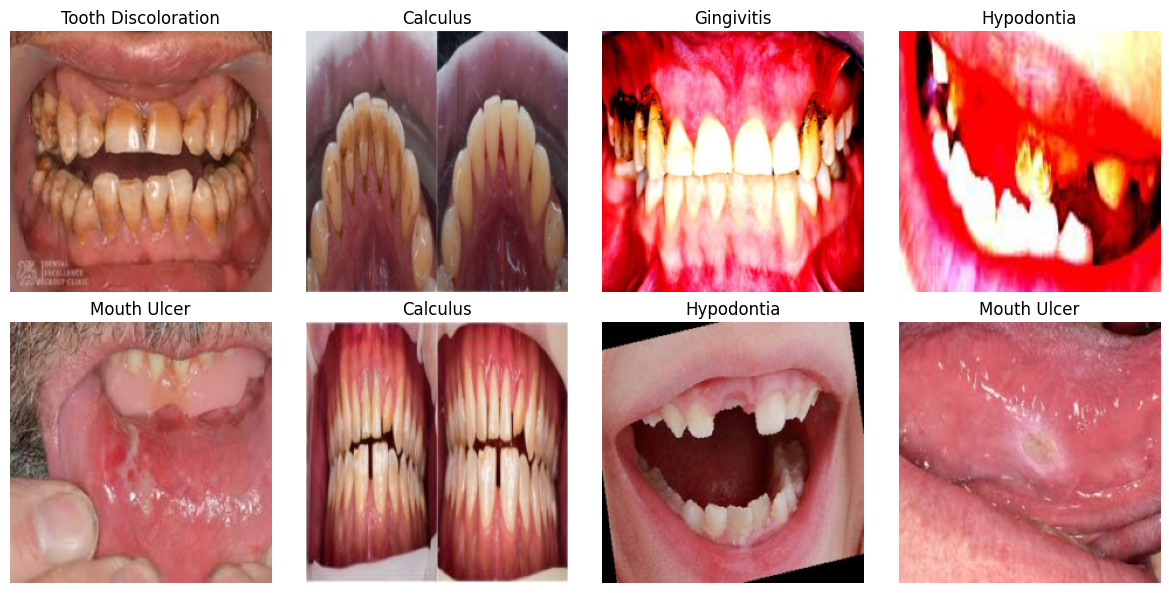

In [10]:
AUTOTUNE = tf.data.AUTOTUNE
CLASS_W = tf.constant(cw, dtype=tf.float32)

def _load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE, antialias=True)
    return tf.cast(tf.round(img), tf.uint8), y            # uint8 => small RAM cache

def make_ds(d, training=False):
    y = d.label.map(cls2id).values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, y))
    ds = ds.map(_load, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(d), seed=SEED, reshuffle_each_iteration=True)

    def finish(img, yy):
        img = tf.cast(img, tf.float32)                    # raw 0..255, models preprocess internally
        onehot = tf.one_hot(yy, NUM_CLASSES)
        if training:
            return img, onehot, tf.gather(CLASS_W, yy)    # per-sample class weight
        return img, onehot

    return ds.map(finish, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE), y

train_ds, y_train = make_ds(train_df, training=True)
val_ds, y_val = make_ds(val_df)
test_ds, y_test = make_ds(test_df)

x, y, w = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.title(class_names[int(tf.argmax(y[i]))]); plt.axis("off")
plt.tight_layout(); plt.show()

In [11]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def make_augment():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomTranslation(0.08, 0.08),
        layers.RandomZoom(0.15),
        layers.RandomContrast(0.2),
        layers.RandomBrightness(0.15, value_range=(0, 255)),
    ], name="augment")

@keras.utils.register_keras_serializable(package="oral")
class BackbonePreprocess(layers.Layer):
    """Backbone-specific preprocessing, saved inside the model (input = raw RGB 0..255)."""
    def __init__(self, kind="none", **kwargs):
        super().__init__(**kwargs)
        self.kind = kind
    def call(self, x):
        x = tf.cast(x, tf.float32)
        if self.kind == "resnet50":
            return keras.applications.resnet50.preprocess_input(x)
        if self.kind == "densenet121":
            return keras.applications.densenet.preprocess_input(x)
        if self.kind == "mobilenetv2":
            return keras.applications.mobilenet_v2.preprocess_input(x)
        return x                                           # EfficientNet rescales internally
    def get_config(self):
        cfg = super().get_config()
        cfg["kind"] = self.kind
        return cfg

class MacroF1(keras.callbacks.Callback):
    """Adds val_macro_f1 to the logs so callbacks can monitor it (must come first in the list)."""
    def __init__(self, ds, y_true):
        super().__init__()
        self.ds, self.y_true = ds, y_true
    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(self.ds, verbose=0).argmax(1)
        logs["val_macro_f1"] = f1_score(self.y_true, pred, average="macro")

MONITOR, MODE = "val_loss", "min"      # your original choice; use ("val_macro_f1", "max") to track macro-F1 instead

def get_callbacks(model_name, patience=7):
    """Your original three callbacks: best-model checkpoint, early stopping, lr reduction."""
    checkpoint = keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / f"{model_name}_best.keras"),
        monitor=MONITOR, save_best_only=True, save_weights_only=False, mode=MODE, verbose=1)
    early_stop = keras.callbacks.EarlyStopping(
        monitor=MONITOR, patience=patience, restore_best_weights=True, mode=MODE, verbose=1)
    reduce_lr = keras.callbacks.ReduceLROnPlateau(
        monitor=MONITOR, factor=0.2, patience=3, min_lr=1e-7, mode=MODE, verbose=1)
    # MacroF1 goes first: it only adds val_macro_f1 to the logs so it can be monitored/printed
    return [MacroF1(val_ds, y_val), checkpoint, early_stop, reduce_lr]

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
                  metrics=["accuracy"])

def predict_probs(model, ds, tta=False):
    p = model.predict(ds, verbose=0)
    if tta:                                                # average with horizontally flipped images
        flipped = ds.map(lambda x, y: (tf.image.flip_left_right(x), y))
        p = (p + model.predict(flipped, verbose=0)) / 2
    return p

def evaluate(model, ds, y_true, title, tta=False, plot=True):
    pred = predict_probs(model, ds, tta).argmax(1)
    out = {"accuracy": accuracy_score(y_true, pred), "macro_f1": f1_score(y_true, pred, average="macro")}
    if plot:
        print(title)
        print(classification_report(y_true, pred, target_names=class_names, digits=4))
        cm = confusion_matrix(y_true, pred)
        fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0])
        sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
                    xticklabels=class_names, yticklabels=class_names, ax=ax[1])
        ax[0].set_title(title + " (counts)"); ax[1].set_title("row-normalised (recall per class)")
        for a in ax:
            a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=45)
        plt.tight_layout(); plt.show()
    return out

def plot_history(hist, title):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for a, (k, t) in zip(ax, [("loss", "Loss"), ("accuracy", "Accuracy"), ("macro_f1", "Macro-F1")]):
        a.plot(hist[k], label="train") if k in hist else None
        a.plot(hist["val_" + k], label="val"); a.set_title(f"{title} - {t}"); a.legend(); a.grid(True)
    plt.tight_layout(); plt.show()

def merge_hist(*hs):
    out = {}
    for h in hs:
        for k, v in h.items():
            out.setdefault(k, []).extend(v)
    return out

results, trained = {}, {}      # filled below: validation metrics + trained models

Epoch 1/60


E0000 00:00:1794190021.416313      50 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CustomCNN_1/dropout_6_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer



Epoch 1: val_loss improved from None to 1.62137, saving model to /kaggle/working/models/CustomCNN_best.keras

Epoch 1: finished saving model to /kaggle/working/models/CustomCNN_best.keras
78/78 - 48s - 612ms/step - accuracy: 0.3671 - loss: 1.7099 - val_accuracy: 0.3141 - val_loss: 1.6214 - val_macro_f1: 0.0797 - learning_rate: 0.0010
Epoch 2/60

Epoch 2: val_loss did not improve from 1.62137
78/78 - 27s - 347ms/step - accuracy: 0.5153 - loss: 1.4771 - val_accuracy: 0.0617 - val_loss: 2.6666 - val_macro_f1: 0.0205 - learning_rate: 0.0010
Epoch 3/60

Epoch 3: val_loss did not improve from 1.62137
78/78 - 28s - 357ms/step - accuracy: 0.6006 - loss: 1.3550 - val_accuracy: 0.1753 - val_loss: 2.7032 - val_macro_f1: 0.1187 - learning_rate: 0.0010
Epoch 4/60

Epoch 4: val_loss did not improve from 1.62137

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
78/78 - 28s - 357ms/step - accuracy: 0.6220 - loss: 1.3025 - val_accuracy: 0.3276 - val_loss: 2.0928 - val_macro

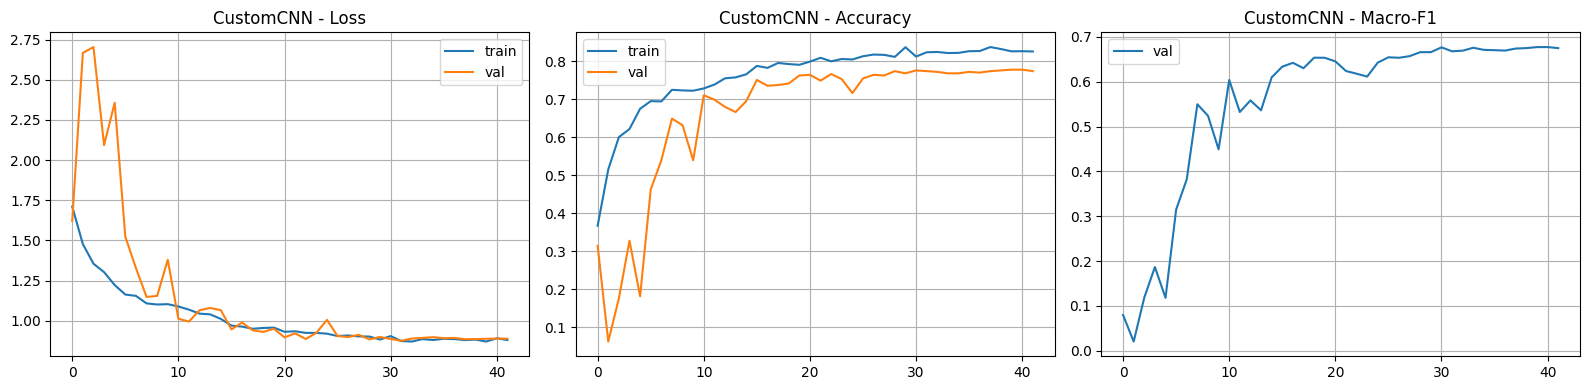

CustomCNN - validation
                     precision    recall  f1-score   support

           Calculus     0.6579    0.6849    0.6711        73
             Caries     0.3182    0.2692    0.2917        26
         Gingivitis     0.8953    0.7662    0.8257       201
         Hypodontia     0.8588    0.8957    0.8769       163
        Mouth Ulcer     0.8000    0.9032    0.8485        31
Tooth Discoloration     0.3864    0.6800    0.4928        25

           accuracy                         0.7746       519
          macro avg     0.6528    0.6999    0.6678       519
       weighted avg     0.7914    0.7746    0.7786       519



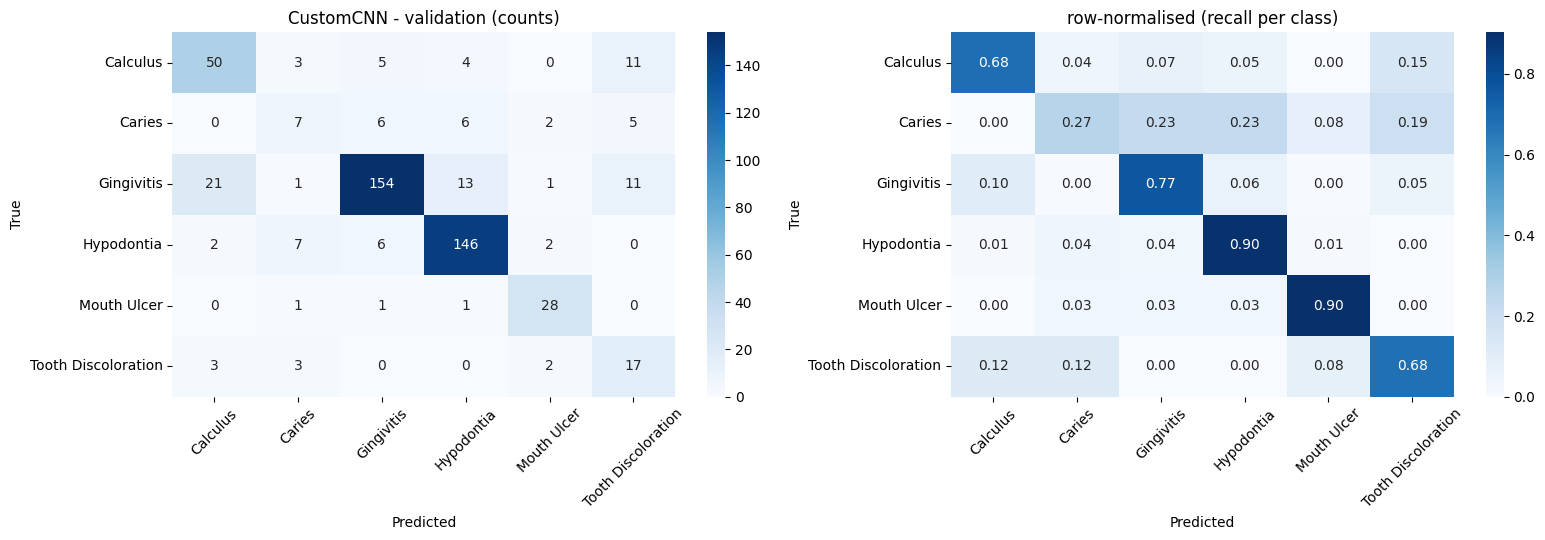

In [13]:
def conv_block(x, f, drop):
    for _ in range(2):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(drop)(x)

def build_custom_cnn():
    inputs = keras.Input((*IMG_SIZE, 3))
    x = make_augment()(inputs)
    x = layers.Rescaling(1 / 255.0)(x)
    for f, d in [(32, 0.1), (64, 0.1), (128, 0.2), (256, 0.2), (256, 0.3)]:
        x = conv_block(x, f, d)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="CustomCNN")

cnn = build_custom_cnn()
compile_model(cnn, 1e-3)
h = cnn.fit(train_ds, validation_data=val_ds, epochs=60, callbacks=get_callbacks("CustomCNN", patience=10), verbose=2)
plot_history(h.history, "CustomCNN")
trained["CustomCNN"] = cnn
results["CustomCNN"] = evaluate(cnn, val_ds, y_val, "CustomCNN - validation")

EfficientNetB0
Epoch 1/10


E0000 00:00:1794191453.128792      50 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5425 - loss: 1.4651
Epoch 1: val_loss improved from None to 0.93153, saving model to /kaggle/working/models/EfficientNetB0_stage1_best.keras

Epoch 1: finished saving model to /kaggle/working/models/EfficientNetB0_stage1_best.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 27s 217ms/step - accuracy: 0.6422 - loss: 1.2708 - val_accuracy: 0.7495 - val_loss: 0.9315 - val_macro_f1: 0.6160 - learning_rate: 0.0010
Epoch 2/10
77/78 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.7504 - loss: 1.0370
Epoch 2: val_loss did not improve from 0.93153
78/78 ━━━━━━━━━━━━━━━━━━━━ 8s 105ms/step - accuracy: 0.7581 - loss: 1.0119 - val_accuracy: 0.7457 - val_loss: 0.9422 - val_macro_f1: 0.6396 - learning_rate: 0.0010
Epoch 3/10
77/78 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.7812 - loss: 0.9461
Epoch 3: val_loss improved from 0.93153 to 0.83901, saving model to /kaggle/working/models/EfficientNetB0_stage1_best.keras

Epoch 3: finished saving model to /kaggle/w

E0000 00:00:1794191562.701016      50 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


77/78 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.9095 - loss: 0.7108
Epoch 1: val_loss improved from None to 0.75623, saving model to /kaggle/working/models/EfficientNetB0_best.keras

Epoch 1: finished saving model to /kaggle/working/models/EfficientNetB0_best.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 31s 226ms/step - accuracy: 0.9184 - loss: 0.7002 - val_accuracy: 0.8516 - val_loss: 0.7562 - val_macro_f1: 0.7515 - learning_rate: 2.0000e-05
Epoch 2/30
77/78 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9217 - loss: 0.6793
Epoch 2: val_loss improved from 0.75623 to 0.74418, saving model to /kaggle/working/models/EfficientNetB0_best.keras

Epoch 2: finished saving model to /kaggle/working/models/EfficientNetB0_best.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 11s 137ms/step - accuracy: 0.9233 - loss: 0.6800 - val_accuracy: 0.8593 - val_loss: 0.7442 - val_macro_f1: 0.7566 - learning_rate: 2.0000e-05
Epoch 3/30
77/78 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.9240 - loss: 0.6543
Epoch 3: val_loss d

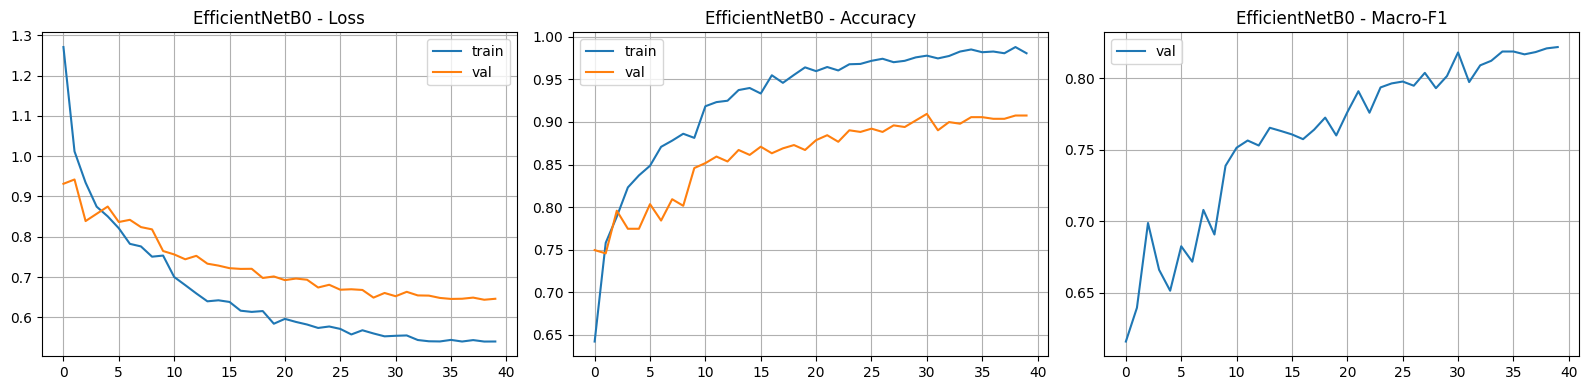

EfficientNetB0 - validation
                     precision    recall  f1-score   support

           Calculus     0.9677    0.8219    0.8889        73
             Caries     0.6522    0.5769    0.6122        26
         Gingivitis     0.9333    0.9751    0.9538       201
         Hypodontia     0.9934    0.9264    0.9587       163
        Mouth Ulcer     0.7692    0.9677    0.8571        31
Tooth Discoloration     0.5758    0.7600    0.6552        25

           accuracy                         0.9075       519
          macro avg     0.8153    0.8380    0.8210       519
       weighted avg     0.9159    0.9075    0.9089       519



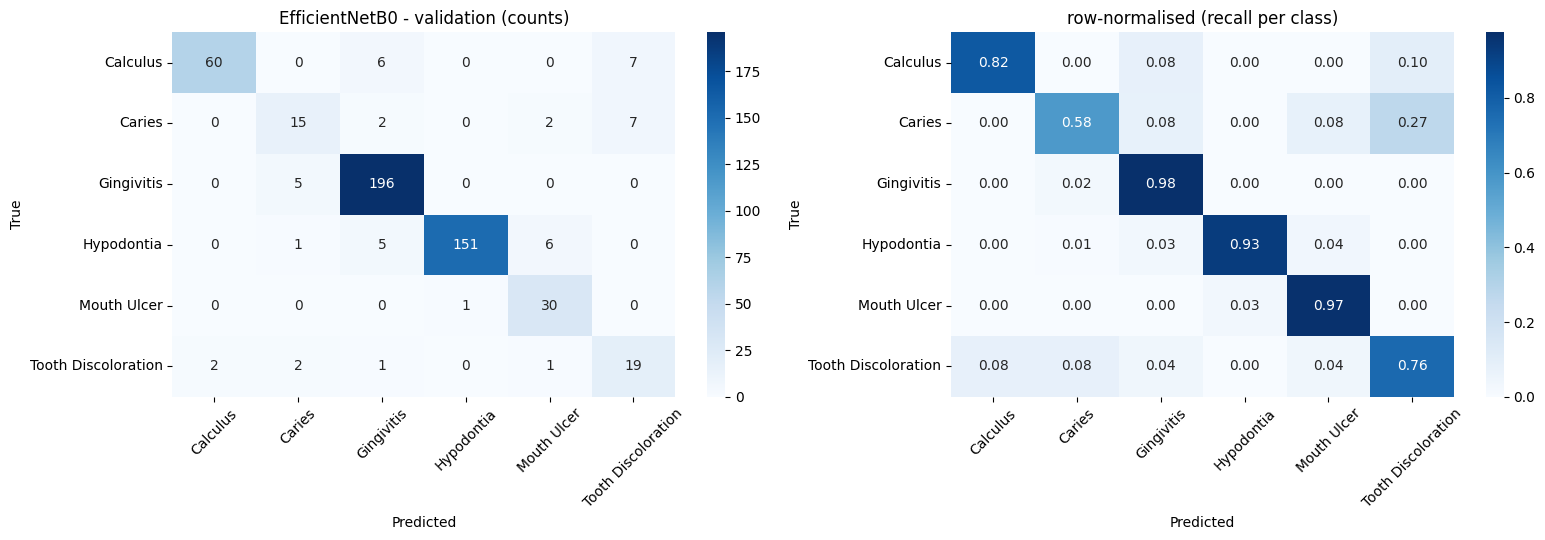

ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.4783 - loss: 1.9287
Epoch 1: val_loss improved from None to 1.13530, saving model to /kaggle/working/models/ResNet50_stage1_best.keras

Epoch 1: finished saving model to /kaggle/working/models/ResNet50_stage1_best.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 30s 292ms/step - accuracy: 0.5913 - loss: 1.4928 - val_accuracy: 0.6493 - val_loss: 1.1353 - val_macro_f1: 0.5671 - learning_rate: 0.0010
Epoch 2/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.6903 - loss: 1.1106
Epoch 2: val_loss improved from 1.13530 to 0.96485, saving model to /kaggle/working/models/ResNet50_stage1_best.keras

Epoch 2: finished saving model to /kaggle/working/models/ResNet50_stage1_best.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 17s 215ms/step - accuracy: 0.7068 - loss: 1.1021 - val_accuracy: 0.7341 - val_loss: 0.9648 - val_macro_f1: 0.5976 - learning_rate: 0.0010
Epoch 3/10
78/78 ━━━━━━━━━━━━━━━━━━

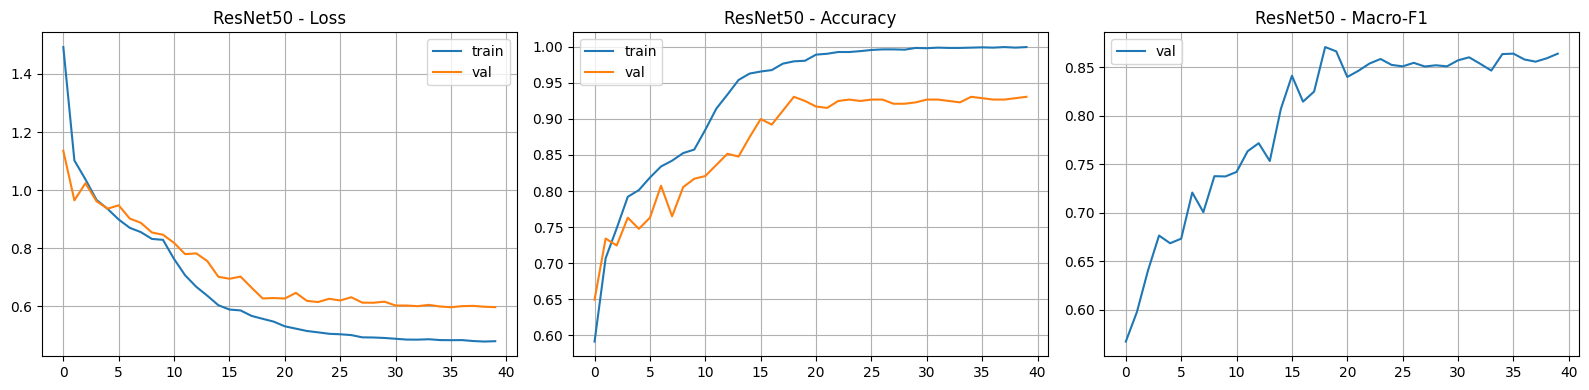

ResNet50 - validation
                     precision    recall  f1-score   support

           Calculus     0.9565    0.9041    0.9296        73
             Caries     0.9286    0.5000    0.6500        26
         Gingivitis     0.9384    0.9851    0.9612       201
         Hypodontia     0.9805    0.9264    0.9527       163
        Mouth Ulcer     0.8611    1.0000    0.9254        31
Tooth Discoloration     0.6571    0.9200    0.7667        25

           accuracy                         0.9287       519
          macro avg     0.8870    0.8726    0.8642       519
       weighted avg     0.9355    0.9287    0.9270       519



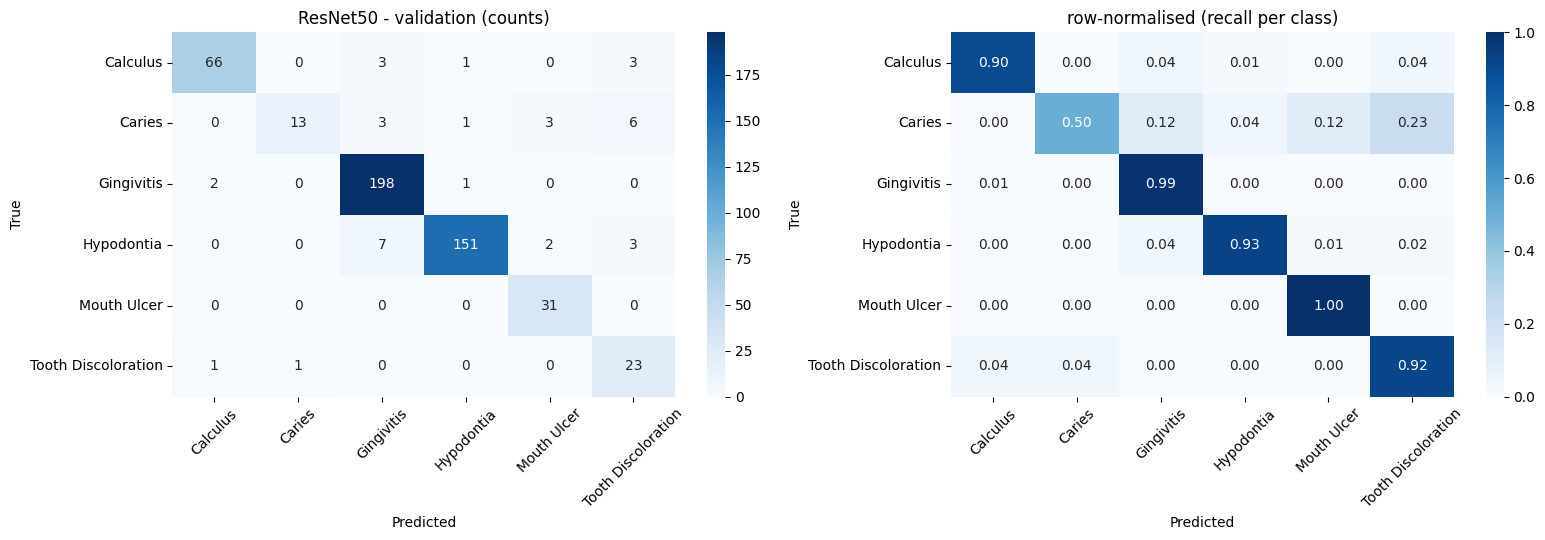

DenseNet121
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.3838 - loss: 2.0055
Epoch 1: val_loss improved from None to 1.15160, saving model to /kaggle/working/models/DenseNet121_stage1_best.keras

Epoch 1: finished saving model to /kaggle/working/models/DenseNet121_stage1_best.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 44s 391ms/step - accuracy: 0.4842 - loss: 1.6674 - val_accuracy: 0.6570 - val_loss: 1.1516 - val_macro_f1: 0.5315 - learning_rate: 0.0010
Epoch 2/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - accuracy: 0.6040 - loss: 1.3282
Epoch 2: val_loss improved from 1.15160 to 1.06799, saving model to /kaggle/working/models/DenseNet121_stage1_best.keras

Epoch 2: finished saving model to /kaggle/working/models/DenseNet121_stage1_best.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 18s 237ms/step - accuracy: 0.6216 - loss: 1.2913 - val_accuracy: 0.6917 - val_loss: 1.0680 - val_macro_f1: 0.5484 - learning_rate: 0.0010
Epoch 3/10
78/78 ━━━

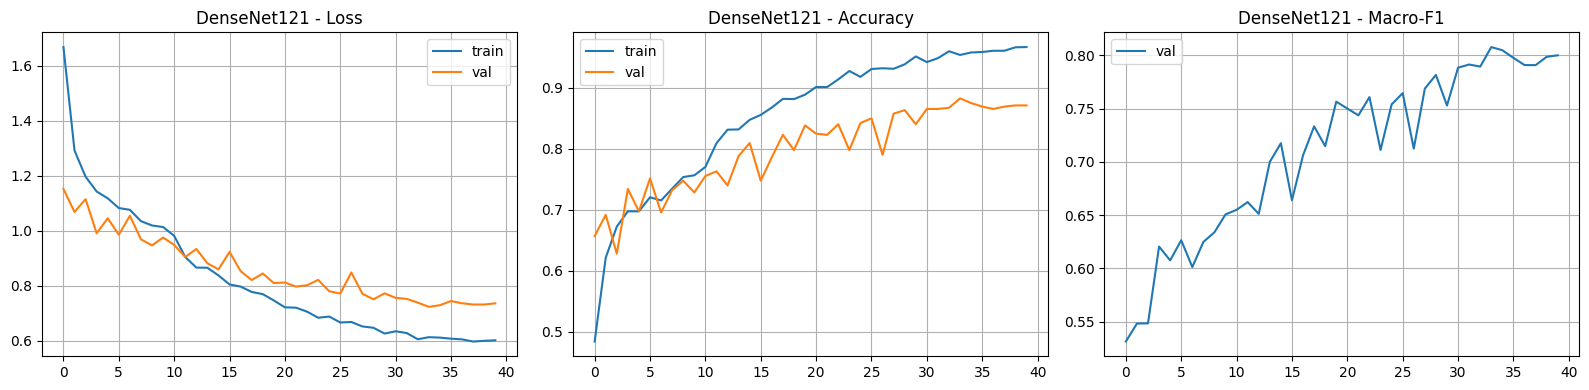

DenseNet121 - validation
                     precision    recall  f1-score   support

           Calculus     0.9375    0.8219    0.8759        73
             Caries     0.6400    0.6154    0.6275        26
         Gingivitis     0.9135    0.9453    0.9291       201
         Hypodontia     0.9861    0.8712    0.9251       163
        Mouth Ulcer     0.8108    0.9677    0.8824        31
Tooth Discoloration     0.4878    0.8000    0.6061        25

           accuracy                         0.8825       519
          macro avg     0.7959    0.8369    0.8077       519
       weighted avg     0.8993    0.8825    0.8869       519



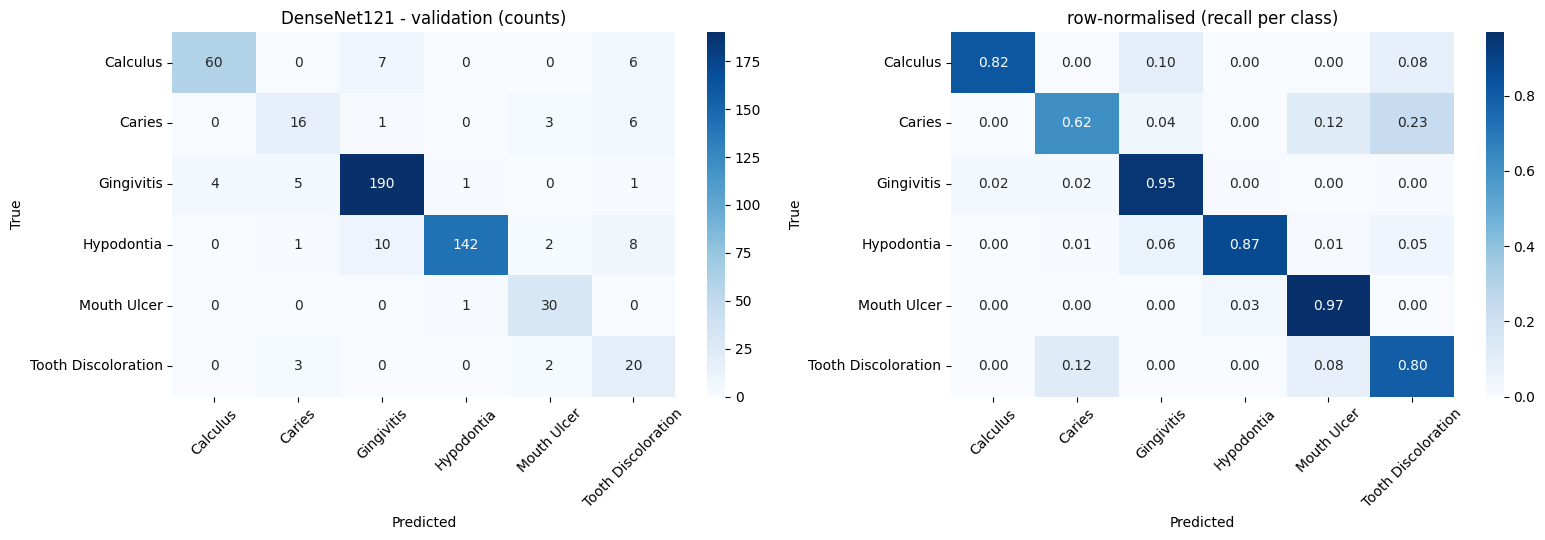

MobileNetV2
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.4856 - loss: 1.6759
Epoch 1: val_loss improved from None to 0.98114, saving model to /kaggle/working/models/MobileNetV2_stage1_best.keras

Epoch 1: finished saving model to /kaggle/working/models/MobileNetV2_stage1_best.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 16s 140ms/step - accuracy: 0.5691 - loss: 1.4412 - val_accuracy: 0.7534 - val_loss: 0.9811 - val_macro_f1: 0.6025 - learning_rate: 0.0010
Epoch 2/10
77/78 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.6968 - loss: 1.1528
Epoch 2: val_loss improved from 0.98114 to 0.90964, saving model to /kaggle/working/models/MobileNetV2_stage1_best.keras

Epoch 2: finished saving model to /kaggle/working/models/MobileNetV2_stage1_best.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 7s 88ms/step - accuracy: 0.7120 - loss: 1.1160 - val_accuracy: 0.7649 - val_loss: 0.9096 - val_macro_f1: 0.6211 - learning_rate: 0.0010
Epoch 3/10
77/78 ━━━━━━━━━

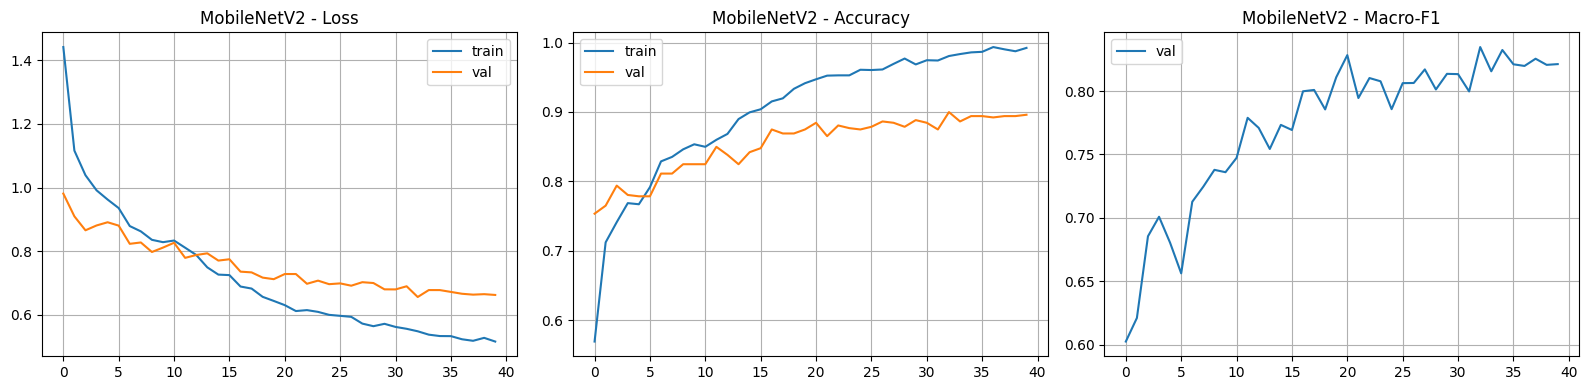

MobileNetV2 - validation
                     precision    recall  f1-score   support

           Calculus     0.9524    0.8219    0.8824        73
             Caries     0.8095    0.6538    0.7234        26
         Gingivitis     0.8728    0.9900    0.9277       201
         Hypodontia     0.9610    0.9080    0.9338       163
        Mouth Ulcer     0.8750    0.9032    0.8889        31
Tooth Discoloration     0.7143    0.6000    0.6522        25

           accuracy                         0.8998       519
          macro avg     0.8642    0.8128    0.8347       519
       weighted avg     0.9010    0.8998    0.8974       519



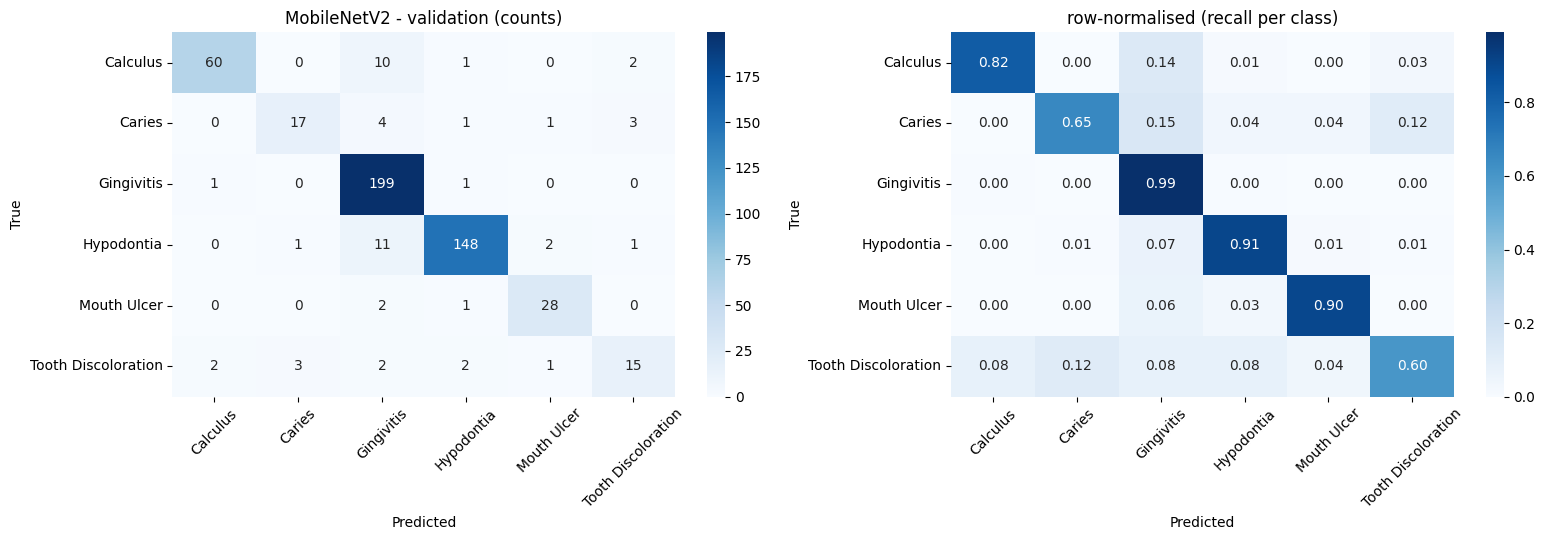

In [15]:
BACKBONES = {
    "EfficientNetB0": (keras.applications.EfficientNetB0, "efficientnet"),
    "ResNet50":       (keras.applications.ResNet50, "resnet50"),
    "DenseNet121":    (keras.applications.DenseNet121, "densenet121"),
    "MobileNetV2":    (keras.applications.MobileNetV2, "mobilenetv2"),
}

def build_tl_model(name, dropout=0.3):
    ctor, kind = BACKBONES[name]
    backbone = ctor(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
    backbone.trainable = False
    inputs = keras.Input((*IMG_SIZE, 3))
    x = make_augment()(inputs)
    x = BackbonePreprocess(kind)(x)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name), backbone

def unfreeze_top(backbone, frac=0.30):
    backbone.trainable = True
    cut = int(len(backbone.layers) * (1 - frac))
    for i, l in enumerate(backbone.layers):
        l.trainable = (i >= cut) and not isinstance(l, layers.BatchNormalization)

def train_backbone(name, head_epochs=10, ft_epochs=30, ft_lr=2e-5):
    print("=" * 70, f"\n{name}\n" + "=" * 70)
    model, backbone = build_tl_model(name)

    compile_model(model, 1e-3)                                          # stage 1: head only
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=head_epochs,
                   callbacks=get_callbacks(name + "_stage1", patience=5), verbose=1)

    unfreeze_top(backbone, 0.30)                                        # stage 2: fine-tune
    compile_model(model, ft_lr)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=ft_epochs,
                   callbacks=get_callbacks(name, patience=8), verbose=1)
    return model, merge_hist(h1.history, h2.history)

MODELS_TO_TRAIN = ["EfficientNetB0", "ResNet50", "DenseNet121", "MobileNetV2"]        # add "MobileNetV2" if you want

for name in MODELS_TO_TRAIN:
    model, hist = train_backbone(name)
    plot_history(hist, name)
    trained[name] = model
    results[name] = evaluate(model, val_ds, y_val, f"{name} - validation")

In [16]:
val_table = pd.DataFrame(results).T.sort_values("macro_f1", ascending=False)
print("VALIDATION"); display(val_table.round(4))

best_name = val_table.index[0]
print("best model on validation:", best_name)

test_table = pd.DataFrame({n: evaluate(m, test_ds, y_test, n, plot=False) for n, m in trained.items()}).T
print("TEST (reported for all models, selection was done on validation)"); display(test_table.loc[val_table.index].round(4))

VALIDATION


,accuracy,macro_f1
ResNet50,0.9287,0.8642
MobileNetV2,0.8998,0.8347
EfficientNetB0,0.9075,0.8210
DenseNet121,0.8825,0.8077
CustomCNN,0.7746,0.6678


best model on validation: ResNet50
TEST (reported for all models, selection was done on validation)


,accuracy,macro_f1
ResNet50,0.9472,0.8925
MobileNetV2,0.8943,0.8301
EfficientNetB0,0.9268,0.8599
DenseNet121,0.8841,0.8265
CustomCNN,0.8313,0.7261


Test, no TTA: {'accuracy': 0.9471544715447154, 'macro_f1': 0.892502819876566}
Test, with flip-TTA: {'accuracy': 0.9471544715447154, 'macro_f1': 0.8849555794228126}
ResNet50 - TEST
                     precision    recall  f1-score   support

           Calculus     0.9310    0.9474    0.9391        57
             Caries     0.8421    0.5926    0.6957        27
         Gingivitis     0.9609    0.9829    0.9718       175
         Hypodontia     1.0000    0.9709    0.9853       172
        Mouth Ulcer     0.9024    1.0000    0.9487        37
Tooth Discoloration     0.7143    0.8333    0.7692        24

           accuracy                         0.9472       492
          macro avg     0.8918    0.8878    0.8850       492
       weighted avg     0.9482    0.9472    0.9459       492



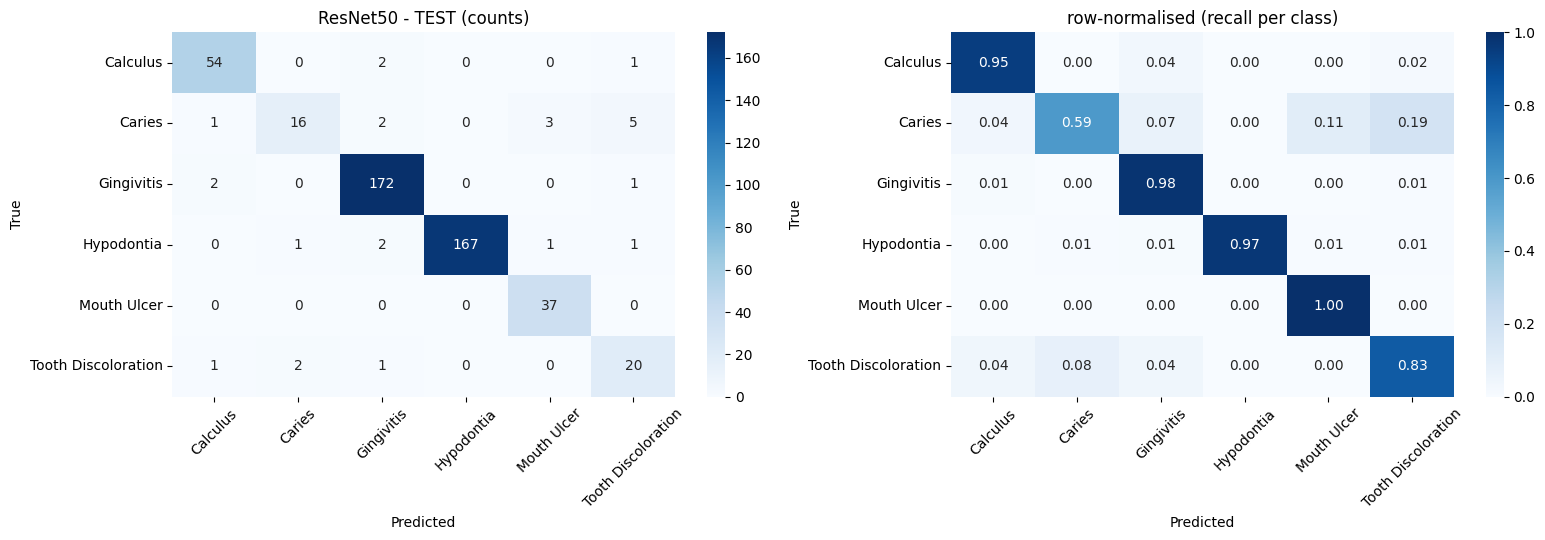

In [17]:
best_model = trained[best_name]
print("Test, no TTA:", evaluate(best_model, test_ds, y_test, best_name, plot=False))
print("Test, with flip-TTA:", evaluate(best_model, test_ds, y_test, best_name, tta=True, plot=False))

_ = evaluate(best_model, test_ds, y_test, f"{best_name} - TEST", tta=True)

In [19]:
best_model.save(MODEL_DIR / "oral_best_model.keras")
with open(MODEL_DIR / "class_names.json", "w") as f:
    json.dump(class_names, f)
print("saved:", os.listdir(MODEL_DIR))

saved: ['CustomCNN_best.keras', 'EfficientNetB0_best.keras', 'DenseNet121_best.keras', 'ResNet50_best.keras', 'EfficientNetB0_stage1_best.keras', 'class_names.json', 'oral_best_model.keras', 'ResNet50_stage1_best.keras', 'MobileNetV2_stage1_best.keras', 'MobileNetV2_best.keras', 'DenseNet121_stage1_best.keras']
